# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [1]:
import json


def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file.

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    texts = []

    for item in data:
        texts.append(item["text"])

    return texts


texts = extract_texts_from_file("resources/data.json")
print(texts)

['Artificial intelligence is changing the world very quickly. AI systems are used in healthcare, finance, education, and transportation.', 'Machine learning is a branch of artificial intelligence. ML algorithms learn patterns from data and can make predictions.', 'Natural language processing helps computers understand human language. NLP is used in chatbots, translation systems, and text analysis.', 'Deep learning uses neural networks with many layers. It is widely used for image recognition, speech recognition, and complex prediction tasks.', 'Computer vision allows machines to analyze images and video. AI systems can detect objects, recognize faces, and classify visual information.', 'Data science combines statistics, programming, and machine learning. It helps companies analyze large amounts of data and make better decisions.']


## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [16]:
import re
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag
from spellchecker import SpellChecker


def process_texts(texts):
    """
    Process the texts.

    Processing includes:
    - Lowercasing
    - Removing punctuation
    - Removing special characters and numbers
    - Handling abbreviations
    - Spelling correction
    - Lemmatization
    """

    lemmatizer = WordNetLemmatizer()
    spell = SpellChecker()

    abbreviations = {
        "ai": "artificial intelligence",
        "ml": "machine learning",
        "nlp": "natural language processing"
    }

    technical_words = {
        "ai",
        "ml",
        "nlp",
        "vlan",
        "vlans",
        "vpn",
        "vpns",
        "wan",
        "lan",
        "routing",
        "switching",
        "router",
        "routers",
        "switch",
        "switches",
        "firewall",
        "firewalls",
        "linux",
        "server",
        "servers",
        "ssh",
        "network",
        "networks",
        "automation",
        "monitoring",
        "artificial",
        "intelligence",
        "machine",
        "learning",
        "algorithm",
        "algorithms",
        "neural",
        "computer",
        "computers",
        "dataset",
        "datasets",
        "chatbot",
        "chatbots",
        "programming"
    }

    processed_texts = []

    for text in texts:

        # 1. Lowercasing
        text = text.lower()

        # 2. Remove punctuation, numbers and special characters
        text = re.sub(r"[^a-z\s]", " ", text)

        # Remove extra spaces
        text = re.sub(r"\s+", " ", text).strip()

        words = text.split()

        # 3. Handle abbreviations
        expanded_words = []

        for word in words:
            if word in abbreviations:
                expanded_words.extend(
                    abbreviations[word].split()
                )
            else:
                expanded_words.append(word)

        # 4. Spelling correction
        corrected_words = []

        for word in expanded_words:

            if word in technical_words or len(word) <= 3:
                corrected_words.append(word)
                continue

            correction = spell.correction(word)

            if correction is not None:
                corrected_words.append(correction)
            else:
                corrected_words.append(word)

        # 5. Conservative lemmatization
        tagged_words = pos_tag(corrected_words)

        final_words = []

        for word, tag in tagged_words:

            # Lemmatize only nouns
            if tag.startswith("N"):
                lemma = lemmatizer.lemmatize(
                    word,
                    wordnet.NOUN
                )
                final_words.append(lemma)
            else:
                final_words.append(word)

        processed_texts.append(
            " ".join(final_words)
        )

    return processed_texts


texts_processed = process_texts(texts)

for i, text in enumerate(texts_processed, start=1):
    print(f"Text {i}: {text}")

Text 1: network engineering includes routing switching vlans vpns and firewall
Text 2: a network engineer configures router switch and vpn connection
Text 3: machine learning us algorithms to learn pattern from data
Text 4: artificial intelligence can be used to automate complex task
Text 5: linux server are often used for network service monitoring and automation


## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """

    vectorizer = TfidfVectorizer()

    tfidf_matrix = vectorizer.fit_transform(texts_processed)

    cosine_matrix = cosine_similarity(tfidf_matrix)

    return cosine_matrix.tolist()


cosine_matrix = calcuate_tfidf(texts_processed)

for row in cosine_matrix:
    print(row)

[1.0, 0.1664738837741307, 0.10577390859716869, 0.058152766882431456, 0.17221937172195287, 0.024027431948868222]
[0.1664738837741307, 0.9999999999999994, 0.028795400412071882, 0.1332727360086361, 0.19905538410653073, 0.32960444926954596]
[0.10577390859716869, 0.028795400412071882, 1.0000000000000002, 0.04518549038354287, 0.07412655570170366, 0.05052480423429449]
[0.058152766882431456, 0.1332727360086361, 0.04518549038354287, 0.9999999999999998, 0.05960971442442404, 0.08535452572239405]
[0.17221937172195287, 0.19905538410653073, 0.07412655570170366, 0.05960971442442404, 1.0000000000000002, 0.116892803878621]
[0.024027431948868222, 0.32960444926954596, 0.05052480423429449, 0.08535452572239405, 0.116892803878621, 1.0]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

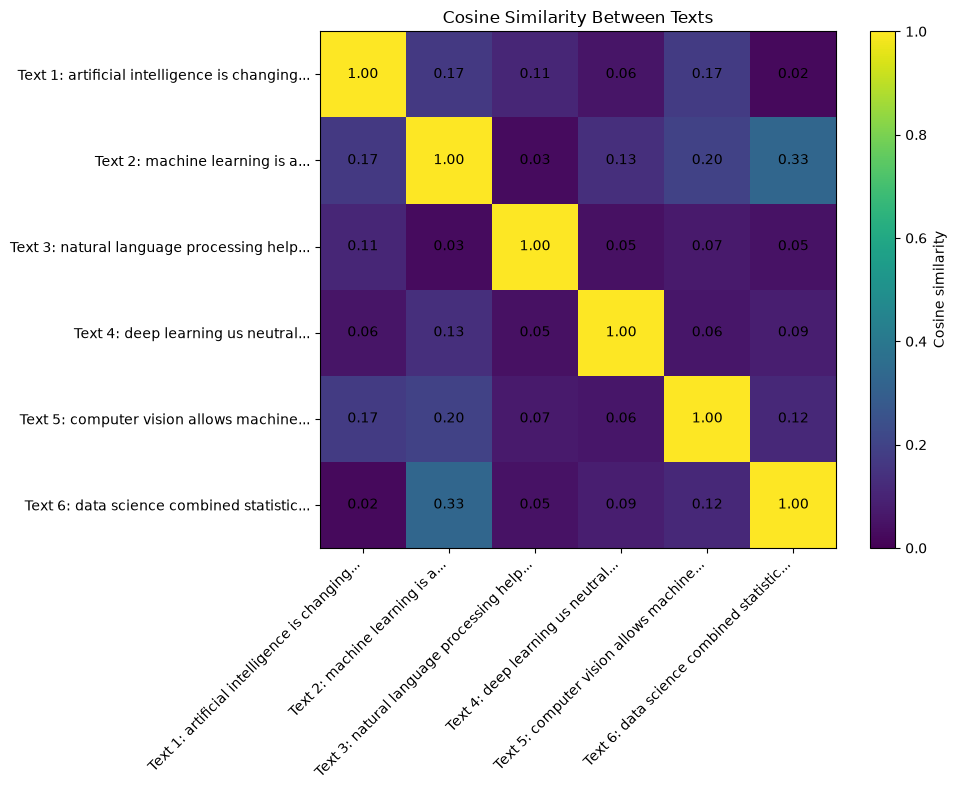

In [7]:
import matplotlib.pyplot as plt
import numpy as np


def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix.

    Args:
        cosine_matrix (list): matrix of cosine similarity scores.
        texts_processed (list): list of processed texts.

    Returns:
        None
    """

    matrix = np.array(cosine_matrix)

    labels = []

    for i, text in enumerate(texts_processed):
        first_words = " ".join(text.split()[:4])
        labels.append(f"Text {i + 1}: {first_words}...")

    plt.figure(figsize=(10, 8))

    plt.imshow(
        matrix,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    plt.colorbar(label="Cosine similarity")

    plt.xticks(
        range(len(labels)),
        labels,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(labels)),
        labels
    )

    for i in range(len(matrix)):
        for j in range(len(matrix)):
            plt.text(
                j,
                i,
                f"{matrix[i, j]:.2f}",
                ha="center",
                va="center"
            )

    plt.title("Cosine Similarity Between Texts")
    plt.tight_layout()

    plt.savefig("cosine_similarity_heatmap.png")
    plt.show()


visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

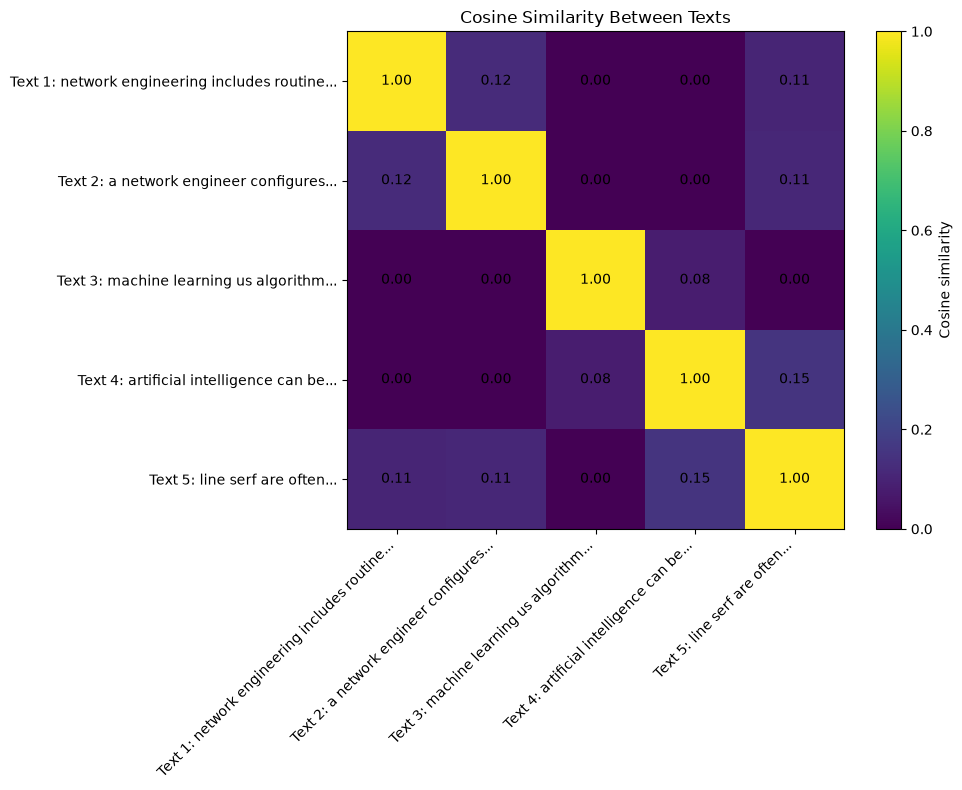

In [8]:
def get_texts():
    """
    Get the texts you want to analyse.

    Returns:
        list: list of texts.
    """

    return [
        "Network engineering includes routing, switching, VLANs, VPNs and firewalls.",
        "A network engineer configures routers, switches and VPN connections.",
        "Machine learning uses algorithms to learn patterns from data.",
        "Artificial intelligence can be used to automate complex tasks.",
        "Linux servers are often used for network services, monitoring and automation."
    ]


texts = get_texts()

texts_processed = process_texts(texts)

cosine_matrix = calcuate_tfidf(texts_processed)

visualize_data(cosine_matrix, texts_processed)